![logo](https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/Helmholtz-AI.png?raw=true)

# Explainability for Random Forest Models

In this notebook, we will show you different methods that can be used for interpreting Random Forest models. We will show you how to compare those methods and choose the appropriate one.

--------

## Getting Started

### Setup Colab environment

If you installed the packages and requirements on your own machine, you can skip this section and start from the import section.
Otherwise, you can follow and execute the tutorial on your browser. In order to start working on the notebook, click on the following button. This will open this page in the Colab environment and you will be able to execute the code on your own.

<a href="https://colab.research.google.com/github/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/xai-for-random-forest/Gen-5-HandsOn_Penguins_XAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Now that you opened the notebook in Colab, run the next cell. It fetches the tutorials and installs the requirements. Running the notebook locally, that cell does nothing: you already have the repository and the requirements.

**Note:** Google Colab may ask you to restart the runtime after installing the required packages. If prompted, restart the runtime before continuing with the notebook.

In [1]:
# On Google Colab: fetch the course and install the requirements.
# Running locally this cell does nothing, because you already have the repository and installed the requirements yourself.
try:
    import google.colab  
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    %cd /content
    !rm -rf XAI-Tutorials
    !git clone --depth 1 --branch main https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials.git
    %cd XAI-Tutorials
    !pip install -r requirements_xai-for-random-forest.txt
    %cd xai-for-random-forest

### Imports

Let's start with importing all required Python packages.

In [2]:
# Load the required packages
import sys
import pickle
import numpy as np
import pandas as pd

import shap
from fgclustering import (
    forest_guided_clustering, 
    forest_guided_feature_importance, 
    plot_forest_guided_clustering,
    plot_forest_guided_feature_importance, 
    plot_forest_guided_decision_paths,
    DistanceRandomForestProximity,
    ClusteringKMedoids,
)
from sklearn.metrics import get_scorer
from sklearn.inspection import permutation_importance

sys.path.append('./')
import utils

# assert reproducible random number generation
seed = 1
np.random.seed(seed)

--------

## Data and Model Loading: The Palmer Penguins Dataset

In this notebook, we will work with the **Palmer penguins dataset**, containing the information on 3 different species of penguins - Adelie, Chinstrap, and Gentoo - which were observed in the Palmer Archipelago near Palmer Station, Antarctica. The dataset consists of a total of 344 penguins, together with their size measurements, clutch observations, and blood isotope ratios. Our goal is to **predict the species** of Palmer penguins and find out the major differences among them.

<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/dataset_penguins.png?raw=true" width="500" /></center>

<font size=1> Source: [Link](https://allisonhorst.github.io/palmerpenguins/)

In the notebook [*Gen-0-Tutorial_RandomForest_Model_Housing_Wine_Penguins.ipynb*](./Gen-0-Tutorial_RandomForest_Model_Housing_Wine_Penguins.ipynb), we explain how to do the exploratory data analysis, preprocess the data and train a Random Forest model with the given data. The focus of this notebook is the interpretation of the previously trained model.

In [3]:
# Load the saved data splits, trained Random Forest classifier, and fitted scaler.
with open('../models/model_rf_penguins.pickle', 'rb') as handle:
    X_train, X_test, y_train, y_test, model_penguins, scaler = pickle.load(handle)

# Compare training and test accuracy to assess performance and generalization.
print(f'Model Performance on training data: {round(model_penguins.score(X_train, y_train)*100,2)} % accuracy.')
print(f'Model Performance on test data: {round(model_penguins.score(X_test, y_test)*100,2)} % accuracy.')

Model Performance on training data: 99.62 % accuracy.
Model Performance on test data: 95.52 % accuracy.


The generalization of our model is very good with 95% test accuracy. However, you should keep in mind that interpreting a low performing model can lead to wrong conclusions.

Below, we plot the correlation between the model features that we should be aware of when using some of the XAI methods.

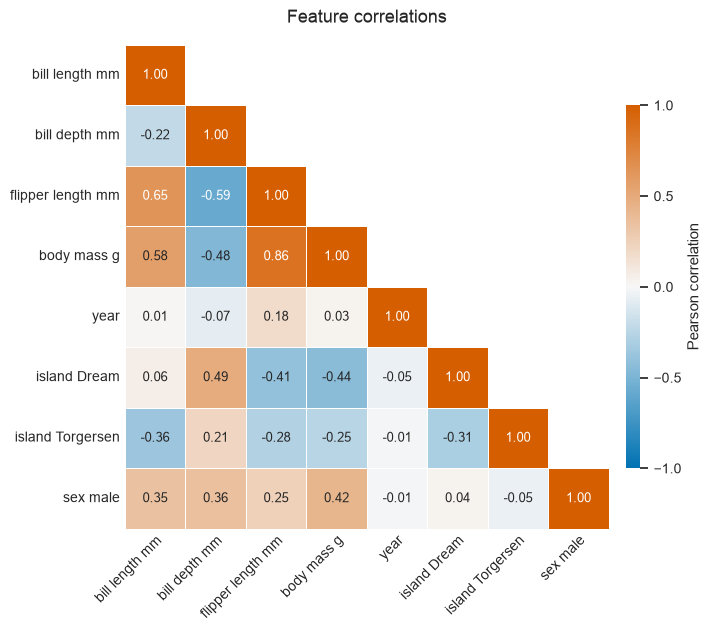

In [4]:
utils.plot_correlation_matrix(X_train)

--------

## Now, what are our possibilities to interpret a Random Forest model?

The goal of the penguins use case is to understand which characteristics distinguish the three penguin species overall, so we are interested in explanations at the dataset and model level rather than explanations for individual predictions. Hence, we focus on **global explanation methods**.

We begin with the built-in **Mean Decrease in Impurity (MDI)** feature importance of Random Forests as a baseline and then compare it with **Permutation Feature Importance**, **SHAP**, and **FGC**. Each method provides a different perspective on how the Random Forest model uses the penguin features for classification.

### Interpretation with Feature Importance Measures

#### Random Forest Feature Importance

A good baseline for interpreting Random Forest models is the built-in feature importance based on the **mean decrease in impurity (MDI)**. The mean decrease in impurity measures how much each feature contributes to reducing node impurity across all trees in the ensemble, averaged over the entire forest. These feature importances are directly provided by the fitted model through the attribute `feature_importances_`.

Let's plot the feature importance based on mean decrease in impurity:

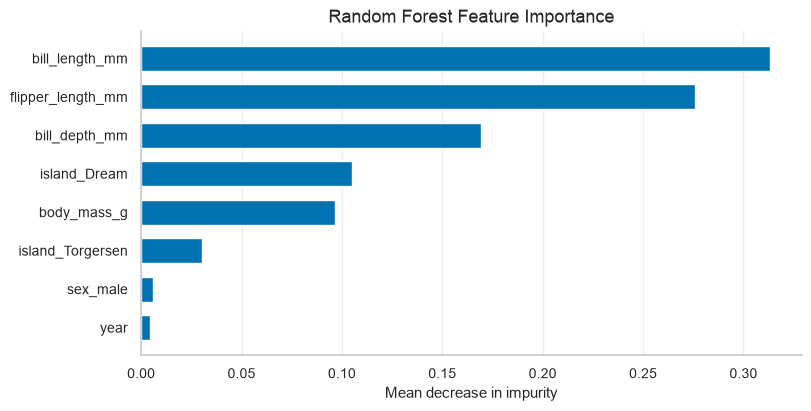

In [5]:
utils.plot_impurity_feature_importance(model_penguins.feature_importances_, names=X_train.columns, title="Random Forest Feature Importance")

#### Permutation Feature Importance

In the [Gen-1-Tutorial_PermutationFeatureImportance.ipynb](./Gen-1-Tutorial_PermutationFeatureImportance.ipynb) notebook you were introduced to the model-agnostic Permutation Feature Importance. Recall, the Permutation Feature Importance is defined to be the decrease in a model score when a single feature value is randomly permuted. This procedure breaks the relationship between the feature and the target. Thus the drop in the model score is indicative of how much the model depends on the feature. Let's now apply it to our penguins dataset:

<font color='green'>

#### Task 1: Use permutation feature importance to investigate which features the trained Random Forest relies on for its predictions.

In [6]:
# TASK: Choose a suitable scoring metric and calculate permutation feature importance
# for the trained penguin classifier using 20 repetitions and the given random seed.
# <add your code here>
scorer = get_scorer("accuracy")
result = permutation_importance(model_penguins, X_train, y_train, n_repeats=20, random_state=seed)

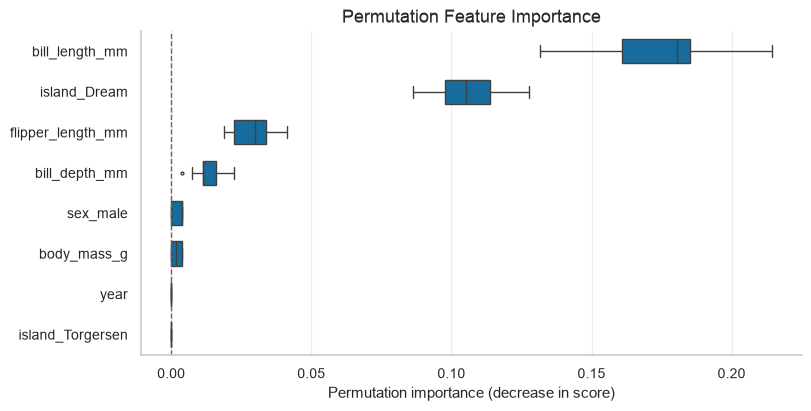

In [7]:
utils.plot_permutation_feature_importance(result=result, data=X_train, title="Permutation Feature Importance")

<font color='green'>

#### Question: Which measurements can we stop collecting?

Imagine that a research team wants to simplify penguin fieldwork by collecting fewer measurements. The team suggests dropping `body_mass_g` because its permutation importance is almost zero. However, it has a nonzero impurity-based importance, and the correlation plot shows a strong relationship with `flipper_length_mm`.

How would you use these results to decide whether body mass can safely be omitted? Explain what might account for the different importance estimates and what you would test before making a recommendation.

</font>

<div style="color: grey; font-size: 0.85em;">

#### Your answer:

The near-zero permutation importance tells us that shuffling body mass barely changes this model’s accuracy on the evaluated data, not that body mass contains no useful information. The model may obtain similar information from flipper length. The two plots measure different things: impurity-based importance summarizes improvements at tree splits, while PFI measures changes in predictive performance. Both can be affected by correlated features, so neither ranking alone settles the decision. We would retrain the model without body mass and compare its performance using the same validation procedure. If performance remains sufficiently good, omitting the measurement may be reasonable. However, we should not assume that both body mass and flipper length can be removed simply because their information overlaps.

</div>

### Interpretation with SHAP

In the [Gen-3-Tutorial_SHAP.ipynb](./Gen-3-Tutorial_SHAP.ipynb) notebook, you were introduced to the model-agnostic SHAP method. Recall, with SHAP we get contrastive explanations that compare the prediction with the average prediction. The global interpretations are consistent with the local explanations, since the Shapley values are the “atomic unit” of the global interpretations.

<font color='green'>

#### Task 2: Analyze the trained Random Forest model using SHAP to understand how the input features contribute to the predictions.

</font>

In [8]:
# TASK: Choose an appropriate SHAP explainer for the Random Forest, define the background data if required, and compute the SHAP values.
# <add your code here>
explainer = shap.TreeExplainer(model=model_penguins, data=shap.maskers.Independent(X_train, max_samples=len(X_train)), model_output="probability")
shap_values = explainer(X_train)

In [9]:
# Convert the scaled feature values back to their original units for easier interpretation
# This only changes the displayed feature values, not the computed SHAP attributions
shap_values.data = pd.DataFrame(scaler.inverse_transform(X_train), columns = X_train.columns).round(4)

In [10]:
# Since we have three penguin species, the model predicts three class probabilities
# SHAP therefore provides a separate baseline (expected value) for each class
ev = explainer.expected_value

# Calculate the average predicted probability for each class over the training data
# This should match the SHAP baselines because we use the full training set as background
pm = np.mean(model_penguins.predict_proba(X_train), axis=0)

print(f'Models average prediction for our data set is for class 0: {round(pm[0],3)}, for class 1: {round(pm[1],3)}, for class 2: {round(pm[2],3)}')
print(f'Expected value for our data set is for class 0: {round(ev[0],3)}, for class 1: {round(ev[1],3)}, for class 2: {round(ev[2],3)}')

Models average prediction for our data set is for class 0: 0.445, for class 1: 0.204, for class 2: 0.351
Expected value for our data set is for class 0: 0.445, for class 1: 0.204, for class 2: 0.351


<Axes: xlabel='mean(|SHAP value|)'>

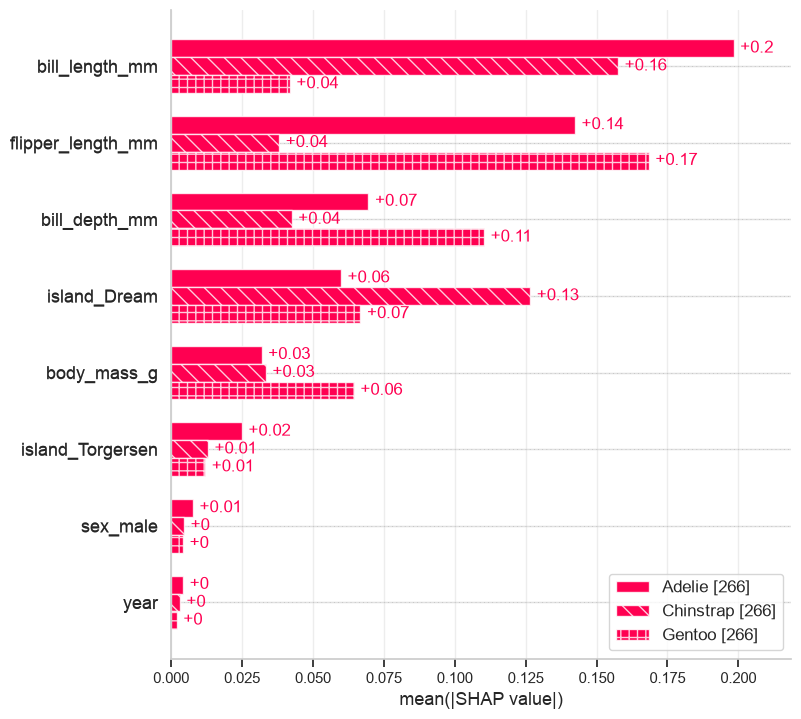

In [11]:
# TASK: Create a global bar plot to compare feature importance across all three penguin species.
# <add your code here>
class_explanations = {
    "Adelie": shap_values[:, :, 0],
    "Chinstrap": shap_values[:, :, 1],
    "Gentoo": shap_values[:, :, 2],
}

shap.plots.bar(class_explanations, show=False)

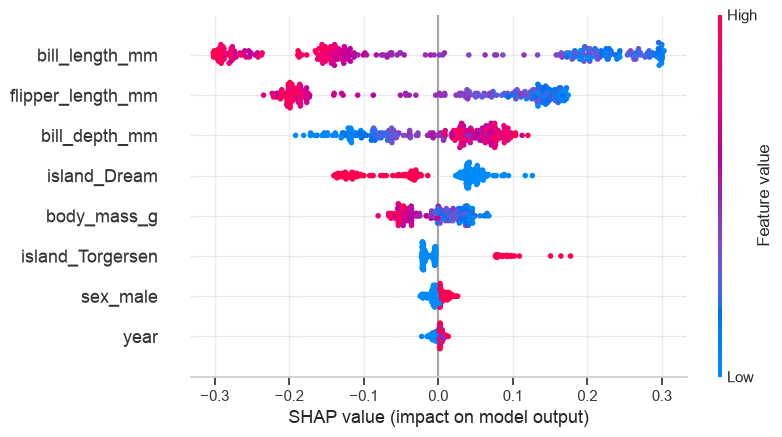

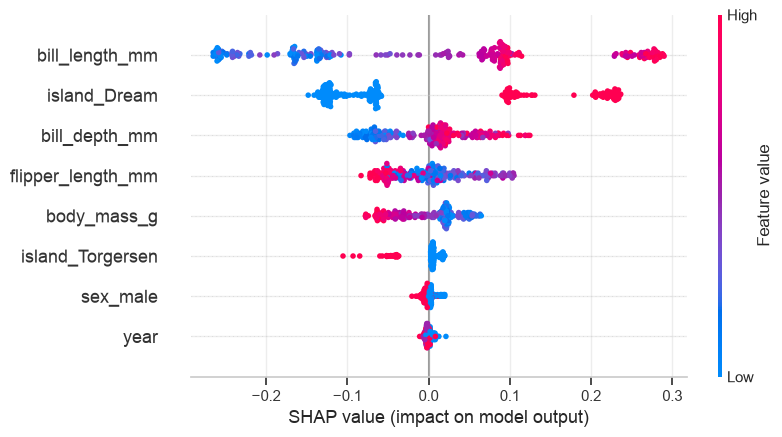

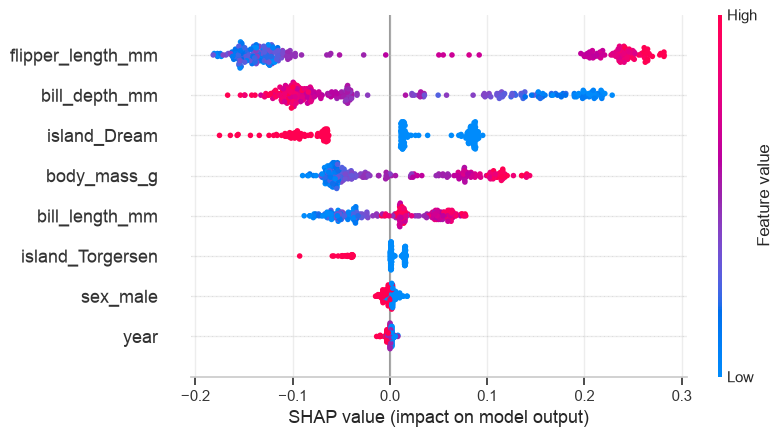

In [12]:
# TASK: Create class-specific beeswarm plots to analyze how feature values influence the predictions for each penguin species.
# <add your code here>
target_class = 0
shap.plots.beeswarm(shap_values[:, :, target_class], show=True)

target_class = 1
shap.plots.beeswarm(shap_values[:, :, target_class], show=True)

target_class = 2
shap.plots.beeswarm(shap_values[:, :, target_class], show=True)

<font color='green'>

#### Question: The global SHAP bar plot identifies `bill_length_mm` as one of the most important features for distinguishing penguin species. However, the beeswarm plots show that high values of this feature decrease the predicted probability for Adelie penguins while increasing it for Chinstrap penguins. How would you interpret these results, and why should we be cautious about drawing conclusions from global feature importance alone?

<font color='grey'>

#### Your Answer:

The global bar plot summarizes the average absolute SHAP values and therefore tells us how strongly a feature contributes to the model's predictions, but not whether it increases or decreases the predicted probability for a particular class. The beeswarm plots provide additional information about the direction and distribution of these contributions. For example, high values of `bill_length_mm` tend to decrease the predicted probability for Adelie penguins while increasing it for Chinstrap penguins. This shows that the same feature can have very different effects depending on which class we explain.

However, these patterns describe how the trained Random Forest uses the features, not necessarily how penguin species can be distinguished in general. In addition, the SHAP values are calculated relative to the class-specific baselines, which in our case are approximately 0.445 for Adelie, 0.204 for Chinstrap, and 0.351 for Gentoo. A positive SHAP value therefore indicates an increase relative to the corresponding class baseline, not necessarily a high predicted probability for that class. The important conclusion is that global feature importance alone is not sufficient to understand model behavior. We also need to consider the direction, distribution, and class-specific nature of the feature contributions. 

</font>

### Interpretation with Forest-Guided Clustering

In the [Gen-4-Tutorial_FGC.ipynb](./Gen-4-Tutorial_FGC.ipynb) notebook you were introduced to the Random Forest specific FGC method. Recall, FGC does not assume independence of model features, because it computes the feature importance based on subgroups of instances that follow similar decision rules within the Random Forest model.

Even though the Random Forest Feature Importance and SHAP do overcome some disadvantages of Permutation Feature Importance and give us some information about class-wise feature contributions, they do not give us further insights into the decision paths of the Random Forest model. Forest-Guided Clustering (FGC) leverages the tree structure of Random Forest models to get insights into the decision making process of the model, which might be able to help us out here... 

<font color='green'>

#### Task 3: Apply Forest-Guided Clustering (FGC) to our trained Random Forest to uncover model-defined subgroups and identify the feature patterns that distinguish them.

In [13]:
# TASK: Run FGC on the training data using a suitable distance measure and
# clustering strategy, evaluating candidate cluster numbers from 2 to 5.
# <add your code here>
fgc = forest_guided_clustering(
    k=(2,5),
    estimator=model_penguins, 
    X=X_train, 
    y=y_train, 
    clustering_distance_metric=DistanceRandomForestProximity(), 
    clustering_strategy=ClusteringKMedoids(method="fasterpam", max_iter=200)
)

Using a sample size of 80.00% of the input data for Jaccard Index computation.
Using range k = (2, 5) to optimize k.


Optimizing k: 100%|██████████| 4/4 [00:22<00:00,  5.71s/it]


Optimal number of clusters k = 3

Clustering Evaluation Summary:
 k    Score  Stable  Mean_JI                                    Cluster_JI
 2 0.359321    True    0.926                          {1: 0.938, 2: 0.915}
 3 0.017445    True    1.000                      {1: 1.0, 2: 1.0, 3: 1.0}
 4 0.026408    True    1.000              {1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0}
 5 0.021126    True    0.989 {1: 0.97, 2: 0.986, 3: 1.0, 4: 0.987, 5: 1.0}


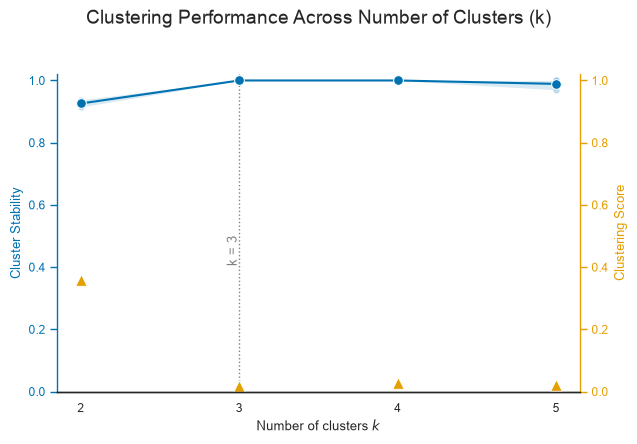

In [14]:
# TASK: Plot the clustering evaluation results to compare target alignment
# and stability across candidate cluster numbers.
# <add your code here>
plot_forest_guided_clustering(
    ks=fgc.ks, 
    scores=fgc.scores, 
    mean_ji=fgc.mean_ji, 
    cluster_jis=fgc.cluster_jis, 
    best_k=fgc.best_k, 
)

In [15]:
# Restore the original feature values from the scaled training data.
X_train_original = scaler.inverse_transform(X_train)
X_train_original = pd.DataFrame(X_train_original, columns = X_train.columns)

# Reconstruct the island categories from the dummy variables. Biscoe is the reference category: both island indicators are 0 for Biscoe.
dummies_island = pd.DataFrame({"Torgersen": X_train_original['island_Torgersen'], "Dream": X_train_original['island_Dream'], "Biscoe": pd.Series(X_train_original['island_Dream'] + X_train_original['island_Torgersen']).replace({0:1, 1:0})})
X_train_original['island'] = pd.Series(dummies_island.columns[np.where(dummies_island!=0)[1]]).astype('category')

# Reconstruct sex: sex_male = 1 represents male, and 0 represents female.
dummies_sex = pd.DataFrame({"male": X_train_original['sex_male'], "female": X_train_original['sex_male'].replace({0:1, 1:0})})
X_train_original['sex'] = pd.Series(dummies_sex.columns[np.where(dummies_sex!=0)[1]]).astype('category')

# Remove the dummy columns now that the original categorical features are restored.
X_train_original = X_train_original.drop(columns=["island_Torgersen", "island_Dream", "sex_male"])

In [16]:
# TASK: Compute feature importance for the selected clustering using the original
# feature values and a distribution distance suitable for mixed feature types.
# <add your code here>
feature_importance = forest_guided_feature_importance(
    X=X_train_original, 
    y=y_train, 
    y_pred=model_penguins.predict(X_train),
    cluster_labels=fgc.cluster_labels[fgc.best_k],
    feature_importance_distance_metric="jensenshannon",
)

100%|██████████| 7/7 [00:00<00:00, 708.34it/s]


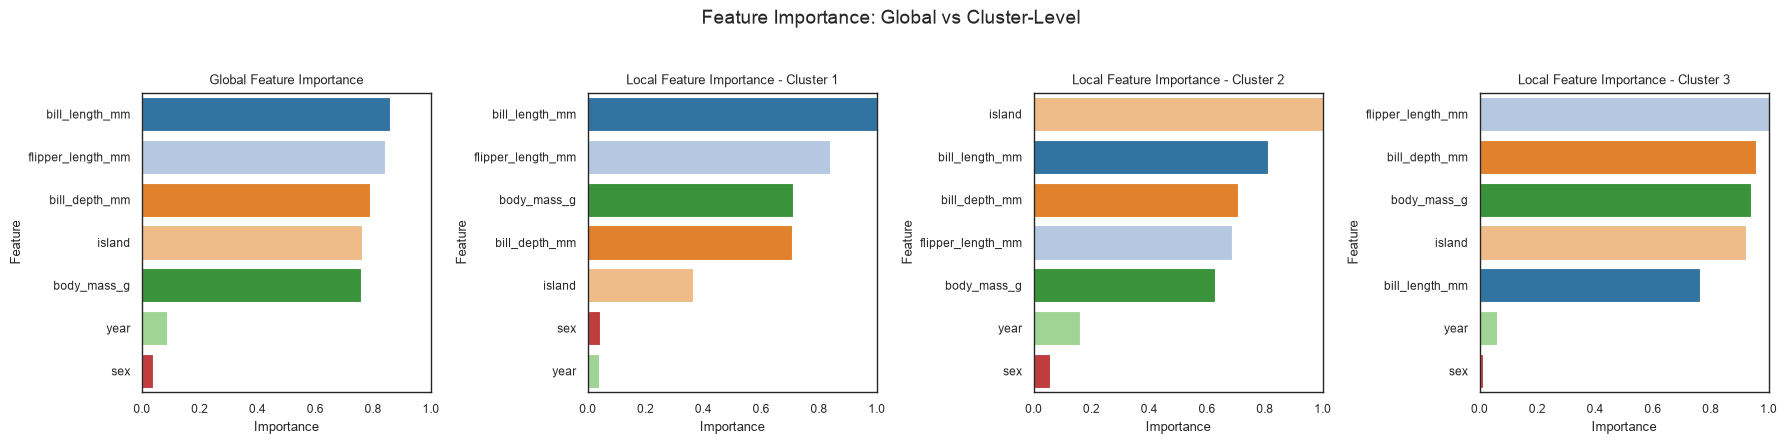

In [17]:
# TASK: Visualize global and cluster-specific feature importance.
# <add your code here>
plot_forest_guided_feature_importance(
    feature_importance_local=feature_importance.feature_importance_local,
    feature_importance_global=feature_importance.feature_importance_global,
    recolor=True,
)

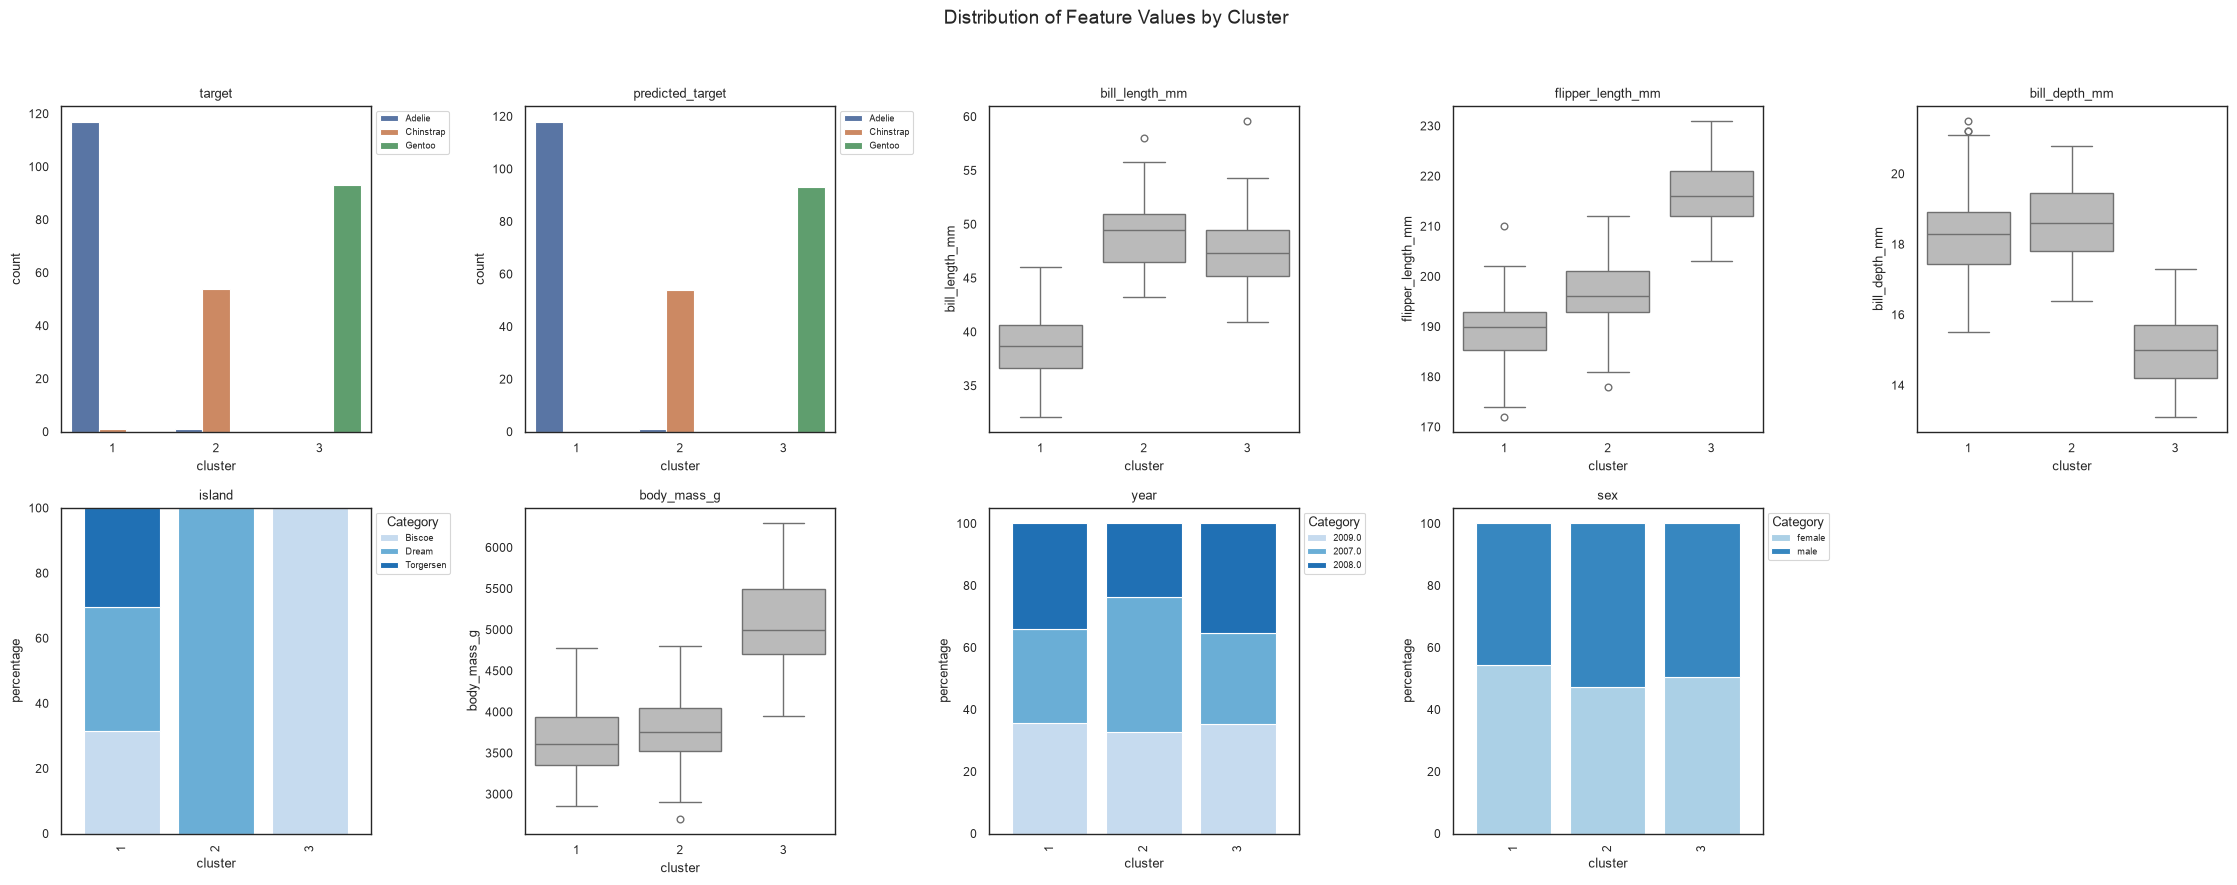

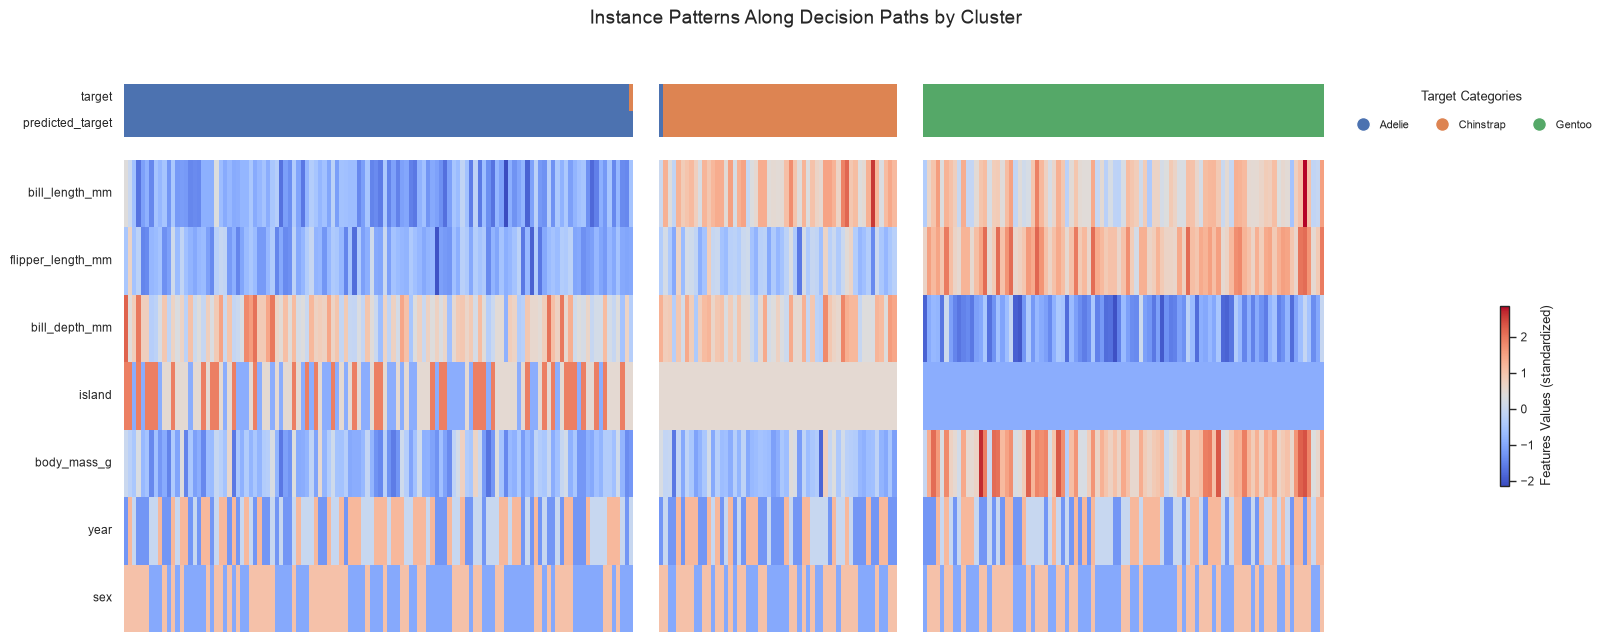

In [18]:
# TASK: Plot a heatmap and feature distributions to explore the patterns that distinguish the clusters.
# <add your code here>
plot_forest_guided_decision_paths(
    data_clustering=feature_importance.data_clustering,
    feature_importance_global=feature_importance.feature_importance_global,
    feature_importance_local=feature_importance.feature_importance_local,
    model_type=fgc.model_type,
    num_cols=5,
    draw_heatmap=True,
    draw_distributions=True,
    draw_dotplot=False,
    color_spec={    
            "color_target_cat": "deep",
            "color_features_cat": "Blues",
        }
)

<font color='green'>

#### Question: What happens if the relationship between island and species changes?

The three FGC clusters closely match the penguin species. Island is especially important for Cluster 2, where all penguins come from Dream Island. Imagine the model now encounters penguins of the same species on another island. Why might their classification be more difficult, even though the FGC clusters are very stable? How could you check whether the model relies too much on island?

</font>

<div style="color: grey; font-size: 0.85em;">

#### Your Answer:

In the training data, island helps distinguish the species. If the model has learned to rely on this relationship, it might struggle when a species appears on a different island. FGC helps us notice this potential issue by highlighting island as a feature that distinguishes the clusters. This does not prove that the model relies too much on island, but it gives us a useful starting point for investigation. We could inspect how island is used in the trees and test the model on penguins with different species–island combinations. Comparing models trained with and without island would provide additional insight.

</div>

<font color='green'>

#### Question: Why do PFI, SHAP, and FGC tell different stories about body mass?

Body mass has almost zero permutation importance, but it contributes to the SHAP explanations for Gentoo and strongly characterizes the Gentoo-dominated FGC cluster. Body mass and flipper length are also strongly correlated. Imagine a colleague concludes: “The methods disagree, so at least one must be unreliable. Since permutation importance is almost zero, we should ignore body mass.”

How would you explain these results to your colleague? What does each method tell us, and what would you check before deciding to remove body mass from the model?

</font>

<div style="color: grey; font-size: 0.85em;">

#### Your Answer:

The methods answer different questions, so different results do not necessarily mean disagreement:

- **PFI** shows that shuffling body mass barely changes the chosen performance score. The model may still classify samples correctly using other information, including correlated flipper length.
- **SHAP** shows how body mass contributes to individual predictions relative to a baseline. These contributions can differ between species without producing a large change in overall classification accuracy.
- **FGC** shows that body mass helps characterize the Gentoo-dominated cluster: these penguins are generally heavier than those in the other clusters.

Together, the methods show that a feature can describe an important subgroup and contribute to predictions without being essential for maintaining the current performance score. Before removing body mass, we could retrain the model without it and compare performance on held-out data, including results for each species. We should also consider its correlation with flipper length. Low PFI alone does not establish that the feature contains no useful information.

More generally, predictive modelling and XAI describe patterns a model learns and uses, not necessarily causal relationships: low model importance does not make a feature scientifically irrelevant, and high importance does not prove that changing it would cause the outcome to change.

</div>